# Machine Learning using Sentinel-2 Data

<div><img src="https://github.com/digitalearthpacific/DigitalEarthPacific/blob/main/notebooks/DEP_LCAST/reference_materials/images/1B/1.a.png?raw=true" width="500"/></div>

This example uses training data from the
[Coast Train](https://github.com/nick-murray/coastTrain) dataset
along with Sentinel-2 data to demonstrate how to use a
machine learning classifier, in this case, Random Forest, to
assign a class to each pixel.

This notebook combines lessons from previous notebooks into
a comprehensive worked example.

## Getting started

First we load the required Python libraries and tools.

In [1]:
from pystac_client import Client
from dask.distributed import Client as DaskClient
from odc.stac import load, configure_s3_access
import geopandas as gpd
import pandas as pd
import numpy as np
import xarray as xr
import folium
import joblib
import matplotlib.pyplot as plt


from sklearn.ensemble import RandomForestClassifier

import odc.geo.xr  # noqa: F401

## Study site configuration

Here we establish the STAC catalog we're using as well as a
spatial and temporal extent. This can be anywhere, but this location
near Kuching was chosen due to the training data having several
classes available.

In [2]:
# STAC Catalog URL
# catalog = "https://stac.staging.digitalearthpacific.org"
catalog = "https://earth-search.aws.element84.com/v1"
# Create a STAC Client
client = Client.open(catalog)

<font color='blue'>1.1. Define your area of interest. Find the coordinates of the bottom left and top right corners of your bounding box / area of interest. 

Use QGIS, Google Maps or another site to find the coordinates. Make sure to use at least 4 or 5 decimal places. Lat = latitude and lon = longitude. The min is in the bottom left and max is in the top right.   

In [3]:
# # 1.1 - input your four coordinates here 
# min_lat = -17.631319
# min_lon = 177.968450
# max_lat = -17.621633
# max_lon = 177.975529

# bbox = (min_lon, min_lat, max_lon, max_lat)

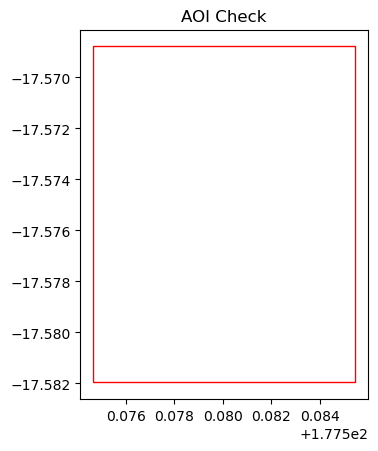

In [4]:
# Define bounding box – should match your area
aoi_gdf = gpd.read_file("AOI/Lololo_2.geojson")
aoi_gdf.plot(edgecolor="red", facecolor="none")
plt.title("AOI Check")
plt.show()  # Replace with actual coordinates

In [5]:
bbox = aoi_gdf.total_bounds  # returns [minx, miny, maxx, maxy]

In [6]:
center = [
    aoi_gdf.geometry.centroid.y.mean(),
    aoi_gdf.geometry.centroid.x.mean()
]

m = folium.Map(location=center, zoom_start=10)

folium.GeoJson(
    aoi_gdf,
    style_function=lambda x: {
        "fillColor": "none",
        "color": "red",
        "weight": 2
    }
).add_to(m)

m

/tmp/ipykernel_389/1827346902.py:2: UserWarning: Geometry is in a geographic CRS. Results from 'centroid' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  aoi_gdf.geometry.centroid.y.mean(),
/tmp/ipykernel_389/1827346902.py:3: UserWarning: Geometry is in a geographic CRS. Results from 'centroid' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  aoi_gdf.geometry.centroid.x.mean()


In [7]:
min_lat = aoi_gdf['geometry'].bounds['miny'].min()
max_lat = aoi_gdf['geometry'].bounds['maxy'].max()
min_lon = aoi_gdf['geometry'].bounds['minx'].min()
max_lon = aoi_gdf['geometry'].bounds['maxx'].max()

<font color='blue'>1.2. Define the time period of interest. 

You can now define the time you are interested in. It is goood to put the format as "year-month"/"year-month". For example "2022-06/2024-09" to get all images covering June 2022 to September 2024. You can try to just choose the flowering months in one year but may have issues with cloud cover. Try different time periods and see what happes. 

In [8]:
# 1.2 - input your datetime here - recommend at least 3 months and max 3 years. 
datetime = "2025-06/2025-12"

In [9]:
# Create local dask cluster to improve data load time. Only run this once.
dask_client = DaskClient(n_workers=1, threads_per_worker=16, memory_limit='16GB')

# Configure S3 access. Cloud defaults is an optimisation, while requester pays is required for Landsat
configure_s3_access(cloud_defaults=True, requester_pays=True)

## Training data

Next up we gather training data. This could be any geospatial point dataset
with a column that is numeric, for the class.

If you'd like to explore the structure of this data, you can run `gdf.head()`
to see the first few rows. The `explore()` function with the `column` argument
will show the data on the map, and change the colour based on that column.

<font color='blue'>2.1. Input your data from the field.  

If you have new data, save your data as a geojson in QGIS and then drag and drop it into the same folder as this notebook in DEP. Then you will have to put the name of the file in the brackets below inside of quotes: eg. `'name.geojson'`   

In [10]:
# 2.1 - input your data file here inside the '' 
gdf = gpd.read_file("Training_Data/Fiji_updated8.geojson", bbox=tuple(bbox))

# gdf = gdf.fillna(0)
gdf.explore(column="Random_Forest", legend=True)

In [11]:
# # 2.1 - input your data file here inside the '' 
# gdf = gpd.read_file('InvasiveClean4.geojson', bbox=bbox)

# # gdf = gdf.fillna(0)
# gdf.explore(column="randomforest", legend=True)

## Find and load Sentinel-2 data

Here we search for Sentinel-2 scenes over our study area and use
Dask to lazy-load them. We're only loading the red, green, blue, nir and swir
bands, along with the scene classification (scl) band.

<font color='blue'>2.2. - define the satellite image collections you wish to use: 

Input your collections name inside the brackets: 

You may try:   
"sentinel-2-c1-l2a" (10mx10m resolution pixels)   
OR   
"landsat-c2-l2" (30mx30m resolution pixels)

<font color='blue'>2.3. - define your cloud cover threshold. We recommend a number somewhere between 10-50. No need for quotes. 

Write this next to "lt": eg. {"lt": 50}} 


In [12]:
# Search for Sentinel-2 data
items = client.search(
    collections=["sentinel-2-c1-l2a"],
    bbox=bbox,
    datetime=datetime,
    query={"eo:cloud_cover": {"lt": 25 }},
).item_collection()

print(f"Found {len(items)} items")

Found 17 items


In [13]:
# Load the data into an xarray Dataset
data = load(
    items,
    measurements=["red", "green", "blue", "nir08", "swir16", "scl"],
    bbox=bbox,
    chunks={"x": 2048, "y": 2048},
    groupby="solar_day",
)

data

<xarray.Dataset> Size: 3MB
Dimensions:      (y: 147, x: 116, time: 17)
Coordinates:
  * y            (y) float64 1kB 8.057e+06 8.057e+06 ... 8.056e+06 8.056e+06
  * x            (x) float64 928B 5.61e+05 5.61e+05 ... 5.621e+05 5.621e+05
    spatial_ref  int32 4B 32760
  * time         (time) datetime64[ns] 136B 2025-06-14T22:31:16.957000 ... 20...
Data variables:
    red          (time, y, x) uint16 580kB dask.array<chunksize=(1, 147, 116), meta=np.ndarray>
    green        (time, y, x) uint16 580kB dask.array<chunksize=(1, 147, 116), meta=np.ndarray>
    blue         (time, y, x) uint16 580kB dask.array<chunksize=(1, 147, 116), meta=np.ndarray>
    nir08        (time, y, x) uint16 580kB dask.array<chunksize=(1, 147, 116), meta=np.ndarray>
    swir16       (time, y, x) uint16 580kB dask.array<chunksize=(1, 147, 116), meta=np.ndarray>
    scl          (time, y, x) uint8 290kB dask.array<chunksize=(1, 147, 116), meta=np.ndarray>

## Data preparation

Now that we have data, we need to clean it up, masking out clouds
and scaling values to between 0-1, which are the valid reflectance
values.

We add a couple of indices too, which will help the machine learning
algorithm.

Note that we still have a lazy-loaded array, and haven't transferred
any data over the network.

In [14]:
# Mask out clouds and scale values

# Apply Sentinel-2 cloud mask
# 1: defective, 3: shadow, 9: high confidence cloud, 10: thin cirrus
mask_flags = [1, 3, 9, 10]

cloud_mask = ~data.scl.isin(mask_flags)
masked = data.where(cloud_mask)

# Apply scaling and clip to valid data, from 0 to 1
scaled = (masked.where(masked != 0) * 0.0001).clip(0, 1)

# Add some indices
scaled["ndvi"] = (scaled.nir08 - scaled.red) / (scaled.nir08 + scaled.red)
# scaled["ndwi"] = (scaled.green - scaled.nir08) / (scaled.green + scaled.nir08)

scaled


<xarray.Dataset> Size: 8MB
Dimensions:      (time: 17, y: 147, x: 116)
Coordinates:
  * y            (y) float64 1kB 8.057e+06 8.057e+06 ... 8.056e+06 8.056e+06
  * x            (x) float64 928B 5.61e+05 5.61e+05 ... 5.621e+05 5.621e+05
    spatial_ref  int32 4B 32760
  * time         (time) datetime64[ns] 136B 2025-06-14T22:31:16.957000 ... 20...
Data variables:
    red          (time, y, x) float32 1MB dask.array<chunksize=(1, 147, 116), meta=np.ndarray>
    green        (time, y, x) float32 1MB dask.array<chunksize=(1, 147, 116), meta=np.ndarray>
    blue         (time, y, x) float32 1MB dask.array<chunksize=(1, 147, 116), meta=np.ndarray>
    nir08        (time, y, x) float32 1MB dask.array<chunksize=(1, 147, 116), meta=np.ndarray>
    swir16       (time, y, x) float32 1MB dask.array<chunksize=(1, 147, 116), meta=np.ndarray>
    scl          (time, y, x) float32 1MB dask.array<chunksize=(1, 147, 116), meta=np.ndarray>
    ndvi         (time, y, x) float32 1MB dask.array<chunksize=(1, 147, 116), meta=np.ndarray>

In [15]:
# Visualise one date, to make sure it looks good.
# This example shows empty areas where we've masked out nodata, but
# note that there are still a lot of clouds coming in!

scaled.isel(time=0).odc.explore(vmin=0, vmax=0.3)

/srv/conda/envs/notebook/lib/python3.11/site-packages/rasterio/warp.py:387: NotGeoreferencedWarning: Dataset has no geotransform, gcps, or rpcs. The identity matrix will be returned.
  dest = _reproject(


## Create a cloud-free composite

The final data preparation step involves creating a temporal
median of the data bands. Here we use `compute()` to process
the data and bring it into memory.

We preview the data in the second cell below.

In [16]:
# Create a median composite, which should get rid of most of the remaining clouds
# Note that this will take a few minutes to complete

median = scaled.median("time").compute()

median

<xarray.Dataset> Size: 480kB
Dimensions:      (y: 147, x: 116)
Coordinates:
  * y            (y) float64 1kB 8.057e+06 8.057e+06 ... 8.056e+06 8.056e+06
  * x            (x) float64 928B 5.61e+05 5.61e+05 ... 5.621e+05 5.621e+05
    spatial_ref  int32 4B 32760
Data variables:
    red          (y, x) float32 68kB 0.1204 0.1128 0.1128 ... 0.1169 0.1161
    green        (y, x) float32 68kB 0.1368 0.1278 0.1277 ... 0.1262 0.1249
    blue         (y, x) float32 68kB 0.1186 0.1152 0.1146 ... 0.1146 0.1151
    nir08        (y, x) float32 68kB 0.541 0.4533 0.4533 ... 0.4508 0.4654
    swir16       (y, x) float32 68kB 0.2444 0.2047 0.2047 ... 0.2167 0.2046
    scl          (y, x) float32 68kB 0.0004 0.0004 0.0004 ... 0.0004 0.0004
    ndvi         (y, x) float32 68kB 0.6249 0.5752 0.5711 ... 0.6008 0.6116

<font color='blue'>3.1. - visualise the resulting median satellite image:

`median.odc.explore(vmin=0, vmax=0.3)`

In [17]:
median.odc.explore(vmin=0, vmax=0.3)

## Mask out Water Line, roadlines, and Settlements

In [ ]:
# Example arrays (replace with your own band data)
B03 = np.random.random((1000,1000))*1000   # Green (560 nm)
B04 = np.random.random((1000,1000))*1000   # Red (665 nm)
B08 = np.random.random((1000,1000))*1000   # NIR (842 nm)
B11 = np.random.random((1000,1000))*1000   # SWIR (1610 nm)


In [ ]:
np.seterr(divide='ignore', invalid='ignore')

# NDWI – Water
NDWI = (B03 - B08) / (B03 + B08)

# NDBI – Built-up
NDBI = (B11 - B08) / (B11 + B08)

# NDBaI – Bare soil / Roads
NDBaI = (B11 - B04) / (B11 + B04)


In [ ]:
# Typical thresholds
water_mask    = NDWI > 0.2
building_mask = NDBI > 0.1
road_mask     = (NDBaI > 0.15) & (NDWI < 0) & (NDBI < 0.2)


In [ ]:
combined_mask = water_mask | building_mask | road_mask


In [ ]:
if combined_mask.shape == median.shape:
    mask_da = xr.DataArray(combined_mask, coords=median.coords, dims=median.dims)
    masked_da = median.where(~mask_da, other=np.nan)

In [ ]:
masked_da

## Prepare training data array

This next step involves extracting observed values from the satellite data
and combining them with our point data, resulting in something like this:

`class, red, green, blue ...`

This structure is then fed into the machine learning classifier.

In [18]:
# First transform the training points to the same CRS as the data
training = gdf.to_crs(median.odc.geobox.crs)

# Next get the X and Y values out of the point geometries
training_da = training.assign(x=training.geometry.x, y=training.geometry.y).to_xarray()

# Now we can use the x and y values (lon, lat) to extract values from the median composite
training_values = (
    median.sel(training_da[["x", "y"]], method="nearest").squeeze().compute().to_pandas()
)

# Join the training data with the extracted values and remove unnecessary columns
training_array = pd.concat([training["Random_Forest"], training_values], axis=1)
training_array = training_array.drop(
    columns=[
        "y",
        "x",
        "spatial_ref",
    ]
)

# Drop rows where there was no data available
training_array = training_array.dropna()

# Preview our resulting training array
training_array.head()

,Random_Forest,red,green,blue,nir08,swir16,scl,ndvi
0,1,0.1175,0.1351,0.11860,0.4206,0.2033,0.0004,0.562772
1,1,0.1175,0.1351,0.11860,0.4206,0.2033,0.0004,0.562772
2,1,0.1175,0.1351,0.11860,0.4206,0.2033,0.0004,0.562772
3,1,0.1175,0.1351,0.11860,0.4206,0.2033,0.0004,0.562772
4,2,0.1169,0.1358,0.11765,0.4961,0.2088,0.0004,0.623414


## Create a classifier and fit a model

We pass in simple numpy arrays to the classifier, one has the
observations (the values of the red, green, blue and so on)
while the other has the classes.

Predictors used for Random Forest:
['red', 'green', 'blue', 'nir08', 'swir16', 'ndvi']

Classes included in 80/20 evaluation:
[1, 2, 5, 6, 8, 9]

Classes excluded from 80/20 evaluation (<5 samples):
[3, 4]

Evaluation class counts:
Random_Forest
1     50
2    212
5     20
6     52
8     88
9     32
Name: count, dtype: int64

DATA SPLIT
Total evaluation observations: 454
Training observations: 363
Testing observations: 91

80/20 HOLD-OUT ACCURACY ASSESSMENT
Overall Accuracy : 0.8022
Macro F1         : 0.7701
Weighted F1      : 0.8018

Classification Report:

              precision    recall  f1-score   support

           1       0.67      0.60      0.63        10
           2       0.82      0.84      0.83        43
           5       0.40      0.50      0.44         4
           6       0.91      1.00      0.95        10
           8       0.81      0.72      0.76        18
           9       1.00      1.00      1.00         6

    accuracy                           0.80        91
  

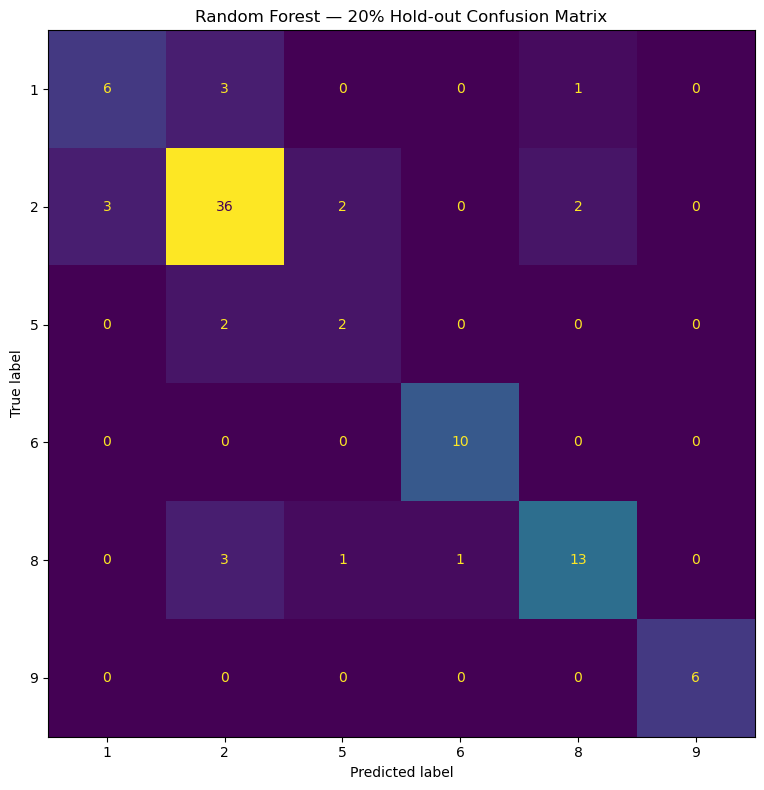


FINAL PRODUCTION MODEL
Training observations: 459
Predictors: 6
Predictor names: ['red', 'green', 'blue', 'nir08', 'swir16', 'ndvi']
Classes: [1 2 3 4 5 6 8 9]


In [19]:
# ============================================================
# RANDOM FOREST — PROPER 80/20 HOLD-OUT ACCURACY ASSESSMENT
# ============================================================

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    f1_score,
)

CLASS_FIELD = "Random_Forest"

# SCL is for cloud masking, not a Random Forest predictor.
predictor_names = [
    col for col in training_array.columns
    if col not in [CLASS_FIELD, "scl"]
]

print("Predictors used for Random Forest:")
print(predictor_names)

# ------------------------------------------------------------
# Exclude extremely small classes from the 80/20 evaluation ONLY.
# The original training_array is left unchanged.
# ------------------------------------------------------------
MIN_CLASS_SAMPLES = 5

class_counts = training_array[CLASS_FIELD].astype(int).value_counts()
valid_classes = class_counts[class_counts >= MIN_CLASS_SAMPLES].index

evaluation_table = training_array[
    training_array[CLASS_FIELD].astype(int).isin(valid_classes)
].copy()

excluded_classes = sorted(
    set(training_array[CLASS_FIELD].astype(int).unique())
    - set(valid_classes)
)

print("\nClasses included in 80/20 evaluation:")
print(sorted(valid_classes.tolist()))

print("\nClasses excluded from 80/20 evaluation (<5 samples):")
print(excluded_classes)

print("\nEvaluation class counts:")
print(
    evaluation_table[CLASS_FIELD]
    .astype(int)
    .value_counts()
    .sort_index()
)

# ------------------------------------------------------------
# 80% training / 20% unseen testing
# ------------------------------------------------------------
X = evaluation_table[predictor_names]
y = evaluation_table[CLASS_FIELD].astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y,
)

print("\n" + "=" * 60)
print("DATA SPLIT")
print("=" * 60)
print("Total evaluation observations:", len(y))
print("Training observations:", len(y_train))
print("Testing observations:", len(y_test))

# ------------------------------------------------------------
# Evaluation model
# ------------------------------------------------------------
evaluation_model = RandomForestClassifier(
    n_estimators=400,
    class_weight="balanced_subsample",
    random_state=42,
    n_jobs=-1,
)

evaluation_model.fit(X_train, y_train)
y_test_pred = evaluation_model.predict(X_test)

accuracy = accuracy_score(y_test, y_test_pred)
macro_f1 = f1_score(y_test, y_test_pred, average="macro", zero_division=0)
weighted_f1 = f1_score(y_test, y_test_pred, average="weighted", zero_division=0)

print("\n" + "=" * 60)
print("80/20 HOLD-OUT ACCURACY ASSESSMENT")
print("=" * 60)
print(f"Overall Accuracy : {accuracy:.4f}")
print(f"Macro F1         : {macro_f1:.4f}")
print(f"Weighted F1      : {weighted_f1:.4f}")

print("\nClassification Report:\n")
print(classification_report(y_test, y_test_pred, zero_division=0))

labels = sorted(y_test.unique())
cm = confusion_matrix(y_test, y_test_pred, labels=labels)

print("Confusion Matrix:")
print(cm)

fig, ax = plt.subplots(figsize=(9, 8))
ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=labels,
).plot(
    ax=ax,
    values_format="d",
    colorbar=False,
)
ax.set_title("Random Forest — 20% Hold-out Confusion Matrix")
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# FINAL PRODUCTION MODEL
# Train using ALL valid original observations after evaluation.
# ------------------------------------------------------------
X_final = training_array[predictor_names]
y_final = training_array[CLASS_FIELD].astype(int)

model = RandomForestClassifier(
    n_estimators=400,
    class_weight="balanced_subsample",
    random_state=42,
    n_jobs=-1,
)

model.fit(X_final, y_final)

# Compatibility with later notebook cells
classes = y_final.to_numpy()
observations = X_final.to_numpy()

print("\n" + "=" * 60)
print("FINAL PRODUCTION MODEL")
print("=" * 60)
print("Training observations:", len(X_final))
print("Predictors:", len(predictor_names))
print("Predictor names:", predictor_names)
print("Classes:", model.classes_)


## Prediction

Next we predict. Again, we need a simple numpy array, this time
just with the observations. This needs to be in long array where
the x dimension is the observation values and the y is each cell
in the original raster.

In [20]:
# ============================================================
# PREDICT THE FULL AOI USING THE SAME TRAINING PREDICTORS
# ============================================================

prediction_data = median[predictor_names]

stacked_arrays = (
    prediction_data
    .to_array("predictor")
    .stack(pixel=["y", "x"])
    .transpose("pixel", "predictor")
)

stacked_values = stacked_arrays.values
valid_pixels = np.all(np.isfinite(stacked_values), axis=1)

predicted = np.full(
    stacked_values.shape[0],
    np.nan,
    dtype="float32",
)

predicted[valid_pixels] = model.predict(
    stacked_values[valid_pixels]
)

array = predicted.reshape(
    len(median.y),
    len(median.x),
)

predicted_da = xr.DataArray(
    array,
    coords={"y": median.y, "x": median.x},
    dims=["y", "x"],
    name="prediction",
)

print("Prediction completed.")
print("Valid predicted pixels:", int(valid_pixels.sum()))


Prediction completed.
Valid predicted pixels: 17052


/srv/conda/envs/notebook/lib/python3.11/site-packages/sklearn/utils/validation.py:2749: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(


## Visualise our results

Here we're visualising the results along with the RGB image
and the original training data points. We're doing this using
a Python library called Folium.

In [21]:
print(predicted_da.dtype)  # Check the dtype of your DataArray
predicted_da = predicted_da.astype('float32')  # Convert to float32

float32


In [22]:
# Put it all on a single interactive map
# center = [np.mean([min_lat[0], max_lat[0]]), np.mean([min_lat[1], max_lat[1]])]
# m = folium.Map(location=center, zoom_start=11)

center = [(min_lat + max_lat) / 2, (min_lon + max_lon) / 2]  # Assuming min_lon and max_lon are defined
m = folium.Map(location=center, zoom_start=11)



# RGB for the median
median.odc.to_rgba(vmin=0, vmax=0.3).odc.add_to(m, name="Median Composite")



<font color='blue'>4.1. - visualise the resulting machine learning prediction:

The name of your model prediction is `predicted_da` so input this before `odc.add_to`

In [23]:
# Categorical for the predicted classes and for the training data
predicted_da.odc.add_to(m, name="Predicted")
gdf.explore(m=m, column="Random_Forest", legend=True, name="Training Data")

# Layer control
folium.LayerControl().add_to(m)

m

<font color='blue'>4.2. - write this model output map to a new file:

Input the name of your model prediction before `.odc.write_cog`

In [24]:
predicted_da.odc.write_cog("Results/Lololo_v6.tif", overwrite=True)
# predicted_da.plot.imshow()

PosixPath('Results/Lololo_v6.tif')

In [25]:
# ============================================================
# ACCURACY NOTE
# ============================================================
# The proper accuracy assessment is now performed earlier using
# the unseen 20% hold-out test set.
#
# Do NOT use predictions on the same observations used to fit
# the final production model as the reported model accuracy.

print(f"Hold-out Overall Accuracy : {accuracy:.4f}")
print(f"Hold-out Macro F1         : {macro_f1:.4f}")
print(f"Hold-out Weighted F1      : {weighted_f1:.4f}")

print("\nThese metrics come from the unseen 20% test observations.")
print("The final production model is then fitted using all valid training observations.")


Hold-out Overall Accuracy : 0.8022
Hold-out Macro F1         : 0.7701
Hold-out Weighted F1      : 0.8018

These metrics come from the unseen 20% test observations.
The final production model is then fitted using all valid training observations.


<font color='blue'>5.1. - download the file, load, explore and set new colours in QGIS:


In [26]:
joblib.dump(model, "cordia_v.2.0.model")

['cordia_v.2.0.model']

## Considerations

Do the results make sense?

What are some of the limitations of the visualisation?

### Next steps

The obvious next step is to fine tune the data. Perhaps download the points for this
region of interest as well as the RGB image and add and remove points until
there is a more representative training dataset.

### New AOI for your interest

Choose a new AoI and ToI based on your interests. This could be for wider Tongatapu, Eua or even Vava'u.  

In [27]:
# 1.1 - input your four coordinates here 
# min_lat = -17.64440
# min_lon = 177.84220
# max_lat = -17.56635
# max_lon = 177.94832

# bbox_nadala = [min_lon, min_lat, max_lon, max_lat]

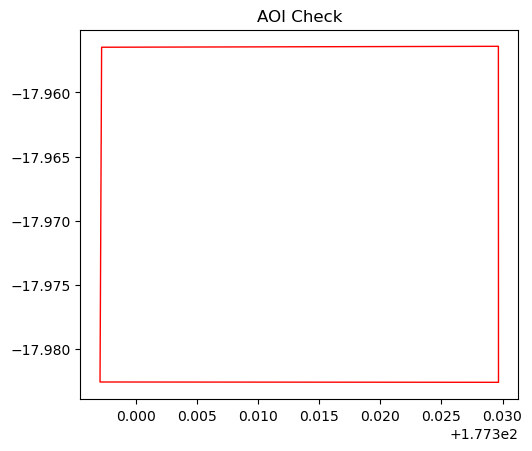

In [28]:
# Define bounding box – should match your elevation mask area
aoiplot_gdf = gpd.read_file("AOI/NabouArea.geojson")
aoiplot_gdf.plot(edgecolor="red", facecolor="none")
plt.title("AOI Check")
plt.show()  # Replace with actual coordinates

In [29]:
min_lat = aoiplot_gdf['geometry'].bounds['miny'].min()
max_lat = aoiplot_gdf['geometry'].bounds['maxy'].max()
min_lon = aoiplot_gdf['geometry'].bounds['minx'].min()
max_lon = aoiplot_gdf['geometry'].bounds['maxx'].max()

In [30]:
bbox_nadala = aoiplot_gdf.total_bounds  # returns [minx, miny, maxx, maxy]

In [31]:
# Search for Sentinel-2 data
items = client.search(
    collections=["sentinel-2-c1-l2a"],
    bbox=bbox_nadala,
    datetime=datetime,
    query={"eo:cloud_cover": {"lt": 25 }},
).item_collection()

print(f"Found {len(items)} items")

Found 17 items


In [32]:
# Load the data into an xarray Dataset
data_nadala = load(
    items,
    measurements=["red", "green", "blue", "nir08", "swir16", "scl"],
    bbox=bbox_nadala,
    chunks={"x": 800, "y": 800},
    groupby="solar_day",
)

# data_Eua

In [33]:
# Mask out clouds and scale values

# Apply Sentinel-2 cloud mask
# 1: defective, 3: shadow, 9: high confidence cloud, 10: thin cirrus
mask_flags = [1, 3, 9, 10]

cloud_mask = ~data_nadala.scl.isin(mask_flags)
masked = data_nadala.where(cloud_mask)

# Apply scaling and clip to valid data, from 0 to 1
scaled_nadala = (masked.where(masked != 0) * 0.0001).clip(0, 1)

# Add some indices
scaled_nadala["ndvi"] = (scaled_nadala.nir08 - scaled_nadala.red) / (scaled_nadala.nir08 + scaled_nadala.red)
# scaled["ndwi"] = (scaled.green - scaled.nir08) / (scaled.green + scaled.nir08)

# Create a median composite, which should get rid of most of the remaining clouds
# Note that this will take a few minutes to complete

median_nadala = scaled_nadala.median("time").compute()

# median

median_nadala.odc.explore(vmin=0, vmax=0.3)

In [34]:
# ============================================================
# PREDICT THE NEW AOI USING EXACTLY THE SAME PREDICTORS
# ============================================================

missing_new = [
    feature for feature in predictor_names
    if feature not in median_nadala.data_vars
]

if missing_new:
    raise ValueError(
        "New AOI is missing model predictors: "
        + ", ".join(missing_new)
    )

prediction_data_nadala = median_nadala[predictor_names]

stacked_arrays_nadala = (
    prediction_data_nadala
    .to_array("predictor")
    .stack(pixel=["y", "x"])
    .transpose("pixel", "predictor")
)

stacked_values_nadala = stacked_arrays_nadala.values
valid_pixels_nadala = np.all(
    np.isfinite(stacked_values_nadala),
    axis=1,
)

predicted_nadala = np.full(
    stacked_values_nadala.shape[0],
    np.nan,
    dtype="float32",
)

predicted_nadala[valid_pixels_nadala] = model.predict(
    stacked_values_nadala[valid_pixels_nadala]
)

array_nadala = predicted_nadala.reshape(
    len(median_nadala.y),
    len(median_nadala.x),
)

predicted_da = xr.DataArray(
    array_nadala,
    coords={
        "y": median_nadala.y,
        "x": median_nadala.x,
    },
    dims=["y", "x"],
    name="prediction",
)

print("New AOI prediction completed.")
print("Valid predicted pixels:", int(valid_pixels_nadala.sum()))


/srv/conda/envs/notebook/lib/python3.11/site-packages/sklearn/utils/validation.py:2749: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(


New AOI prediction completed.
Valid predicted pixels: 100977


In [35]:
print(predicted_da.dtype)  # Check the dtype of your DataArray
predicted_da = predicted_da.astype('float32')  # Convert to float32

# Put it all on a single interactive map
# center = [np.mean([min_lat[0], max_lat[0]]), np.mean([min_lat[1], max_lat[1]])]
# m = folium.Map(location=center, zoom_start=11)

center = [(min_lat + max_lat) / 2, (min_lon + max_lon) / 2]  # Assuming min_lon and max_lon are defined
m = folium.Map(location=center, zoom_start=11)

# RGB for the median
median_nadala.odc.to_rgba(vmin=0, vmax=0.3).odc.add_to(m, name="Median Composite")


float32


In [36]:
# Categorical for the predicted classes and for the training data
predicted_da.odc.add_to(m, name="Predicted")
gdf.explore(m=m, column="Random_Forest", legend=True, name="Training Data")

# Layer control
folium.LayerControl().add_to(m)

m

In [37]:
predicted_da.odc.write_cog("Results/NabouArea_v2.tif", overwrite=True)
# predicted_da.plot.imshow()

PosixPath('Results/NabouArea_v2.tif')